# GRASP for the CVRPTW: Solomon benchmark on the team protocol

**CesiCDP, ADEME call for expressions of interest, delivery route optimization.**
Owner of this notebook: **Farida** (GRASP, experimental study, deck). Team: Pablo (model,
exact method, Tabu Search), Dag (shared base, Simulated Annealing).

## 1. Introduction

### The problem
A depot sends identical trucks of capacity $Q$ to serve $n$ customers. Customer $i$ has a
demand $q_i$, a service duration $s_i$ and a time window $[e_i, l_i]$: service may not start
after $l_i$, and a truck that arrives before $e_i$ **waits on site**. Every customer is served
exactly once, every route starts and ends at the depot inside its window $[e_0, l_0]$, and at
most $K$ trucks are used. This is the CVRPTW (Level A of the brief); without windows it is the
CVRP (Level B). Both are NP-hard (the TSP is the special case $K = 1$, $Q = \infty$; see
notebook 01).

### Objective used in this notebook
Notebook 01 defines the team objective as the **total route duration with time-dependent
traffic**. For the Solomon benchmark we minimize the **total distance** instead (travel time =
distance, no traffic), because the best known solutions (BKS) of Solomon are distance values:
only with the same objective is the gap to the BKS valid. This is the same objective and the
same evaluation as Tabu Search and Simulated Annealing.

### Method
GRASP (Greedy Randomized Adaptive Search Procedure, Feo and Resende, 1995) is a multi-start
method: each iteration builds a solution with a randomized greedy heuristic, improves it with a
local search, and keeps the best feasible solution found. **GRASP-ILS** adds a short iterated
local search inside each iteration (Section 4.3). Both are the same code, `src/cvrp/grasp.py`.

### Team protocol (shared with Tabu Search and SA, `experiments/solomon_study.py`)
| Item | Value |
|---|---|
| Instances | all 56 Solomon instances (C1, C2, R1, R2, RC1, RC2), $n = 100$ |
| Distances | Euclidean, **truncated to one decimal** (the convention of the BKS) |
| Tuning set | C101, C201, R101, R201, RC101, RC201 (first instance of each class) |
| Test set | the other 50 instances, never used to choose a parameter |
| Seeds | 2 per tuning run, 10 per test run |
| Time limit | **20 s per run**, the same for every algorithm |
| Feasibility | every returned solution is checked by the shared `Solution.violations` |

## 2. Imports and configuration

`RECOMPUTE = True` runs every experiment from scratch, on `WORKERS` parallel processes (one
CPU core left free, never more processes than cores, so that every run really gets its 20 s).
Expected time: (144 tuning runs + 500 test runs) × 20 s / `WORKERS`, for example about
30 minutes with 7 workers. `RECOMPUTE = False` reloads the CSV files written by a previous
run in `results/`.

`QUICK_CHECK = True` only checks that the notebook runs end to end (1 s per run, fewer seeds):
its numbers are **not** valid results.

In [1]:
import sys
import time
from pathlib import Path

# Repository root = the folder that contains src/cvrp, wherever the kernel starts.
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "cvrp").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "experiments"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vrplib
from scipy import stats

import solomon_study as study            # team protocol: instances, split, seeds, time limit
from cvrp import Instance, Solution
from cvrp import grasp as G
from cvrp.grasp import GRASPParams, grasp
from cvrp.utils import gap_percent
from cvrp.viz import plot_routes

pd.set_option("display.precision", 2)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True})
# Validated colorblind-safe palette: one color per family, type 2 drawn lighter.
FAMILY_COLOR = {"C": "#2a78d6", "R": "#eb6834", "RC": "#1baf7a"}
VARIANT_COLOR = {"GRASP": "#9a9a96", "GRASP-ILS": "#2a78d6"}
CLASSES = ["C1", "C2", "R1", "R2", "RC1", "RC2"]
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print("project folder:", ROOT.name)

ImportError: DLL load failed while importing dtypes: An Application Control policy has blocked this file.

In [ ]:
RECOMPUTE = True        # True: run everything (needed for the final version); False: reload CSVs
QUICK_CHECK = False     # True: 1 s per run and fewer seeds, only to test the notebook
WORKERS = study.WORKERS # parallel runs; lower it if the laptop must stay usable

TIME_LIMIT = 1.0 if QUICK_CHECK else study.TIME_LIMIT          # 20 s per run (team rule)
TUNING = study.TUNING                                            # 6 tuning instances
TUNE_SEEDS = study.TUNE_SEEDS[:1] if QUICK_CHECK else study.TUNE_SEEDS
TEST_SEEDS = study.TEST_SEEDS[:2] if QUICK_CHECK else study.TEST_SEEDS
GRID = study.ALGORITHMS["grasp"][1]                              # GRASP tuning grid
TAG = "_quick" if QUICK_CHECK else ""                            # quick runs never overwrite real ones
study.WORKERS = WORKERS
print(f"time limit {TIME_LIMIT:.0f} s, {WORKERS} workers, tuning seeds {TUNE_SEEDS}, "
      f"test seeds {TEST_SEEDS[0]}..{TEST_SEEDS[-1]}, grid {GRID}")

time limit 20 s, 7 workers, tuning seeds [101, 102], test seeds 1..10, grid {'alpha': [0.1, 0.3, 0.5], 'improvement': ['first', 'best'], 'perturb_kicks': [0, 90]}


## 3. Dataset loading

The 56 Solomon instances and their BKS files (`data/solomon/<name>.txt` and `.sol`) come from
the PyVRP/VRPLIB copy listed in `data/README.md`; they are git-ignored, so each person downloads
them once. `study.load` reads an instance with the team loader and truncates the distances to
one decimal.

**Convention check.** For every instance, the published BKS routes are evaluated with our
distance matrix and the shared evaluator: the cost must equal the published value and the
solution must be feasible. If this check passes, our gaps compare like with like.

In [ ]:
names = sorted(p.stem for p in study.DATA.glob("*.txt"))
missing = sorted(set(study.TUNING) - set(names))
assert len(names) == 56 and not missing, (
    f"{len(names)} Solomon files found in data/solomon (56 expected); see data/README.md")

rows = []
for name in names:
    inst = study.load(name)
    bks = Solution([list(r) for r in vrplib.read_solution(str(study.DATA / f"{name}.sol"))["routes"]])
    rows.append({"Dataset": name, "Class": name[:-2],  # C101 -> C1, RC205 -> RC2
                 "Set": "tuning" if name in TUNING else "test", "BKS": inst.best_known,
                 "BKS routes": len(bks), "Our cost of the BKS": round(bks.cost(inst), 2),
                 "BKS feasible": bks.is_feasible(inst),
                 "Window width (mean)": float(np.mean(inst.due_times[1:] - inst.ready_times[1:])),
                 "Horizon l0": inst.due_times[0]})
instances = pd.DataFrame(rows)
ok = (instances["BKS feasible"] & np.isclose(instances["Our cost of the BKS"], instances.BKS)).all()
print(f"{len(instances)} instances; BKS reproduced and feasible on all of them: {ok}")
(instances.groupby("Class")
          .agg(instances=("Dataset", "size"), tuning=("Set", lambda s: (s == "tuning").sum()),
               BKS_routes=("BKS routes", "mean"), window=("Window width (mean)", "mean"),
               horizon=("Horizon l0", "first"))
          .reindex(CLASSES).round(1))

56 instances; BKS reproduced and feasible on all of them: True


,instances,tuning,BKS_routes,window,horizon
Class,,,,,
C1,9,1,10.0,321.0,1236.0
C2,8,1,3.0,920.5,3390.0
R1,12,1,13.2,87.0,230.0
R2,11,1,5.5,453.7,1000.0
RC1,8,1,12.5,85.4,240.0
RC2,8,1,6.2,369.8,960.0


Type 1 classes (C1, R1, RC1) have a short horizon, so many trucks with short routes; type 2
classes (C2, R2, RC2) have a long horizon, so few trucks with long routes (about 30 customers
each), which makes each route harder to optimize.

## 4. GRASP implementation

The code is in `src/cvrp/grasp.py`. It reads the shared `Instance`, returns a shared `Solution`
and never modifies the teammates' modules. Pseudocode:

```
GRASP(instance, alpha, time limit):
    best = None
    while the time limit is not reached:
        S = RandomizedGreedyConstruction(alpha)        # 4.1
        if S uses more than K trucks: EliminateRoutes(S)
        S = LocalSearch(S)                             # 4.2 (VND)
        repeat perturb_kicks times (GRASP-ILS only):   # 4.3
            S' = LocalSearch(Kick(S));  if cost(S') < cost(S): S = S'
        if S is feasible (shared evaluator) and cost(S) < cost(best): best = S
    return best
```

### 4.1 Randomized adaptive construction
*Parallel insertion.* For every unrouted customer $u$ the code keeps its cheapest feasible
insertion in every open route, $c(u) = \min_{(a,b)} d_{au} + d_{ub} - d_{ab}$. After an
insertion only the modified route is re-evaluated: this is the **adaptive** part of GRASP.

*Score (regret).* The score of $u$ is $c_1(u) - (c_2(u) - c_1(u))$, with $c_1, c_2$ its best
and second best route: a customer with a large regret has only one good route left, so it is
served before that route fills up.

*Restricted candidate list.* $\text{RCL} = \{u : \text{score}(u) \le s_{\min} + \alpha\,(s_{\max} - s_{\min})\}$;
one customer is drawn at random from the RCL. $\alpha = 0$ is pure greedy, $\alpha = 1$ is random.

*New routes.* When no customer fits anywhere, a route is opened with a seed customer drawn among
the farthest from the depot or the earliest due ones.

### 4.2 Local search: granular Variable Neighborhood Descent

| Neighborhood | Move | Routes |
|---|---|---|
| Relocate | move one customer next to one of its neighbors | intra and inter |
| Swap | exchange two customers | inter |
| 2-opt* | exchange the tails of two routes | inter |
| Or-opt | move a chain of 2 or 3 consecutive customers | inter |
| Cross-exchange | exchange two segments of up to 2 customers | inter |
| 2-opt | reverse a segment | intra |

After any improvement the descent restarts from the first neighborhood; it stops when none
improves. `improvement="first"` applies the first improving move found, `"best"` the best one of
the whole neighborhood. Moves are only tried between a customer and its 20 nearest customers
(granular neighborhoods, Toth and Vigo 2003).

**O(1) time-window check.** Each route stores, at each position $k$, the service start $A_k$
and the latest feasible start $Z_k$ (Savelsbergh 1992):

$$A_k = \max\big(e_{p_k},\; A_{k-1} + s_{p_{k-1}} + d_{p_{k-1} p_k}\big), \qquad
Z_k = \min\big(l_{p_k},\; Z_{k+1} - s_{p_k} - d_{p_k p_{k+1}}\big).$$

Inserting $u$ between positions $k$ and $k+1$ is feasible if and only if
$t_u = \max(e_u, A_k + s_{p_k} + d_{p_k u}) \le l_u$ and $t_u + s_u + d_{u\,p_{k+1}} \le Z_{k+1}$.
The same test checks swap, Or-opt, cross-exchange and 2-opt* without re-simulating routes.
These caches only speed up the search: every kept solution is re-checked by the shared evaluator.

### 4.3 GRASP-ILS: intensification inside each iteration
With `perturb_kicks > 0`, after the descent the solution receives up to that many kicks: remove
a cluster of 10 to 20 % of the customers (a seed and its nearest neighbors), reinsert them at
their cheapest feasible place, descend again, and keep the result only if it is shorter. This is
an Iterated Local Search inside each GRASP iteration, a documented hybridization (Resende and
Ribeiro, 2010). `perturb_kicks = 0` is the plain GRASP. Section 6 compares both at the same
time budget.

### 4.4 Step by step on C101
One construction, then one local search:

construction : cost    987.8, 11 routes, feasible True, 16 ms
local search : cost    886.4, 11 routes, feasible True, 16 improving moves, 13 ms   (BKS 827.3)


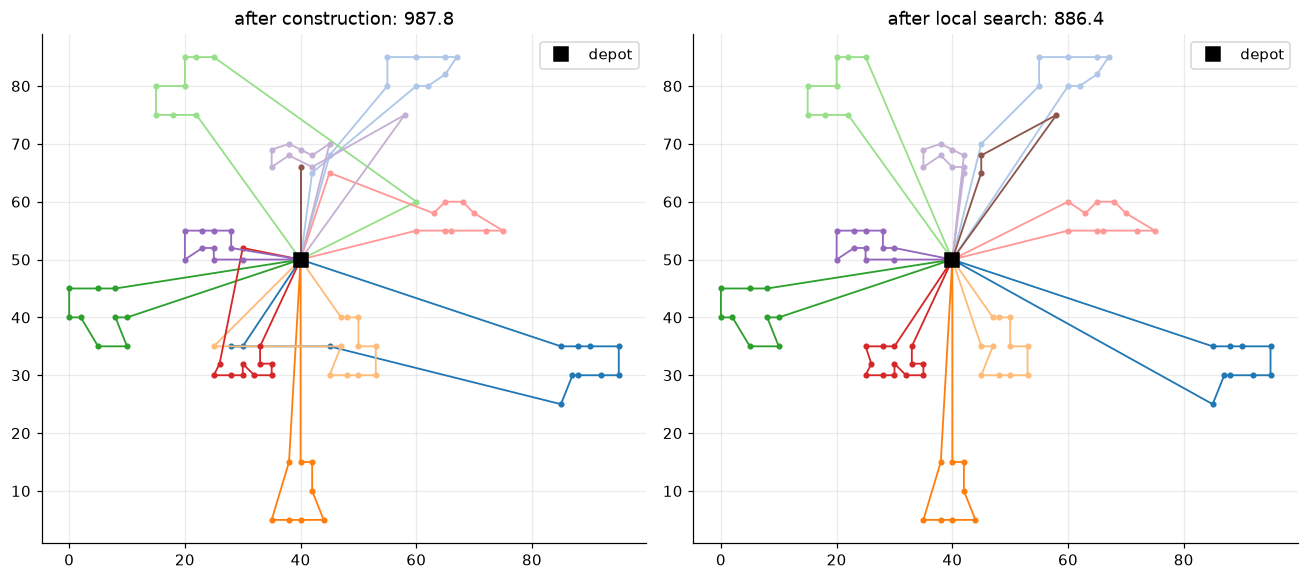

In [ ]:
import random

inst = study.load("C101")
params = GRASPParams(alpha=0.1)
model = G._Model(inst, params.n_neighbors)
rng = random.Random(42)

t = time.perf_counter()
state = G.construct(model, rng, params.alpha, params.construction, params.tw_weight)
built = state.to_solution()
print(f"construction : cost {built.cost(inst):8.1f}, {len(built)} routes, "
      f"feasible {built.is_feasible(inst)}, {(time.perf_counter() - t) * 1000:.0f} ms")
t = time.perf_counter()
moves = G._LocalSearch(model, state, rng, params).run()
improved = state.to_solution()
print(f"local search : cost {improved.cost(inst):8.1f}, {len(improved)} routes, "
      f"feasible {improved.is_feasible(inst)}, {moves} improving moves, "
      f"{(time.perf_counter() - t) * 1000:.0f} ms   (BKS {inst.best_known})")

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_routes(inst, built, ax=axes[0], title=f"after construction: {built.cost(inst):.1f}")
plot_routes(inst, improved, ax=axes[1], title=f"after local search: {improved.cost(inst):.1f}")
plt.tight_layout(); plt.show()

The local search removes the crossings and the long edges between clusters; both phases take
milliseconds on 100 customers, which leaves room for many iterations within 20 s.

## 5. Single-instance testing

Quick debugging entry point: one instance, one variant, one seed, the team time limit.

RC101, GRASP-ILS, seed 1, limit 20 s
  feasible: True   violations: none
  routes 17, distance 1641.4, BKS 1619.8, gap 1.33 %, 15 GRASP iterations in 20.0 s


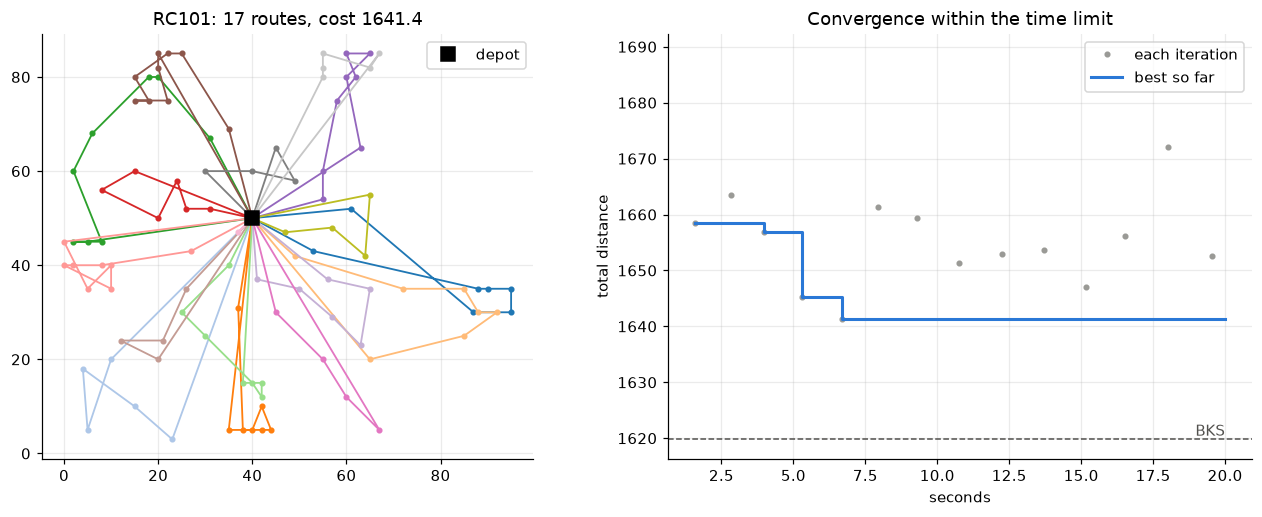

In [ ]:
INSTANCE = "RC101"
KICKS = 90            # 0 = plain GRASP, 90 = GRASP-ILS
SEED = 1

inst = study.load(INSTANCE)
res = grasp(inst, GRASPParams(alpha=0.1, perturb_kicks=KICKS, iterations=10**9,
                              time_limit=TIME_LIMIT), seed=SEED)
sol = res.best
print(f"{INSTANCE}, {'GRASP-ILS' if KICKS else 'GRASP'}, seed {SEED}, limit {TIME_LIMIT:.0f} s")
print(f"  feasible: {sol.is_feasible(inst)}   violations: {sol.violations(inst) or 'none'}")
print(f"  routes {len(sol)}, distance {res.cost:.1f}, BKS {inst.best_known}, "
      f"gap {gap_percent(res.cost, inst.best_known):.2f} %, "
      f"{res.iterations} GRASP iterations in {res.runtime:.1f} s")

h = pd.DataFrame(res.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_routes(inst, sol, ax=axes[0])
axes[1].plot(h.seconds, h.after_ls, "o", ms=3, color="#9a9a96", label="each iteration")
axes[1].step(h.seconds, h.best, where="post", lw=2, color=VARIANT_COLOR["GRASP-ILS"], label="best so far")
axes[1].axhline(inst.best_known, ls="--", lw=1, color="#52514e")
axes[1].annotate("BKS", (h.seconds.max(), inst.best_known), ha="right", va="bottom", color="#52514e")
axes[1].set_xlabel("seconds"); axes[1].set_ylabel("total distance")
axes[1].set_title("Convergence within the time limit"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 6. Parameter tuning (tuning set only, 20 s per run)

Grid: $\alpha \in \{0.1, 0.3, 0.5\}$ × improvement $\in$ {first, best} × kicks $\in \{0, 90\}$,
on the 6 tuning instances with 2 seeds: 144 runs, all with the **same 20 s budget**, so every
comparison below is at equal time. The chosen parameters are those with the lowest mean gap
(`study.best_params`, the same rule as for Tabu Search).

In [ ]:
def with_limit(jobs):
    # Quick check only: shorten every run; real runs keep the team time limit.
    return [(n, a, dict(p, time_limit=TIME_LIMIT), s) for n, a, p, s in jobs] if QUICK_CHECK else jobs


tune_csv = RESULTS / f"solomon_tuning_grasp{TAG}.csv"
if RECOMPUTE:
    jobs = [(n, a, p, s) for n, a, p, s in study.tune_jobs(["grasp"]) if s in TUNE_SEEDS]
    tuning = study.run(with_limit(jobs), tune_csv)
else:
    tuning = pd.read_csv(tune_csv)
tuning["params"] = tuning["params"].str.replace(", 'time_limit': 1.0", "", regex=False)
p = tuning["params"].apply(eval)
tuning["alpha"] = p.str["alpha"]; tuning["improvement"] = p.str["improvement"]
tuning["kicks"] = p.str["perturb_kicks"]
tuning["variant"] = np.where(tuning.kicks > 0, "GRASP-ILS", "GRASP")
print(f"{len(tuning)} tuning runs, all feasible: {tuning.feasible.all()}, "
      f"runtime {tuning.seconds.min():.1f} to {tuning.seconds.max():.1f} s")
summary6 = (tuning.groupby(["variant", "alpha", "improvement"])
                  .agg(mean_gap=("gap", "mean"), worst_gap=("gap", "max"),
                       iterations=("iterations", "mean"))
                  .reset_index().sort_values("mean_gap"))
summary6

144 runs x 20 s on 7 workers, Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
25/144
50/144
75/144
100/144
125/144
144/144
144 tuning runs, all feasible: True, runtime 20.0 to 20.4 s


,variant,alpha,improvement,mean_gap,worst_gap,iterations
9,GRASP-ILS,0.3,first,1.65,5.12,8.33
7,GRASP-ILS,0.1,first,1.78,5.31,8.42
10,GRASP-ILS,0.5,best,1.92,6.55,7.17
11,GRASP-ILS,0.5,first,1.92,6.32,8.25
6,GRASP-ILS,0.1,best,1.98,6.75,7.17
8,GRASP-ILS,0.3,best,2.08,6.37,7.42
3,GRASP,0.3,first,2.71,10.11,145.75
5,GRASP,0.5,first,2.97,8.34,131.00
1,GRASP,0.1,first,3.16,9.73,154.92
4,GRASP,0.5,best,3.55,9.13,54.25


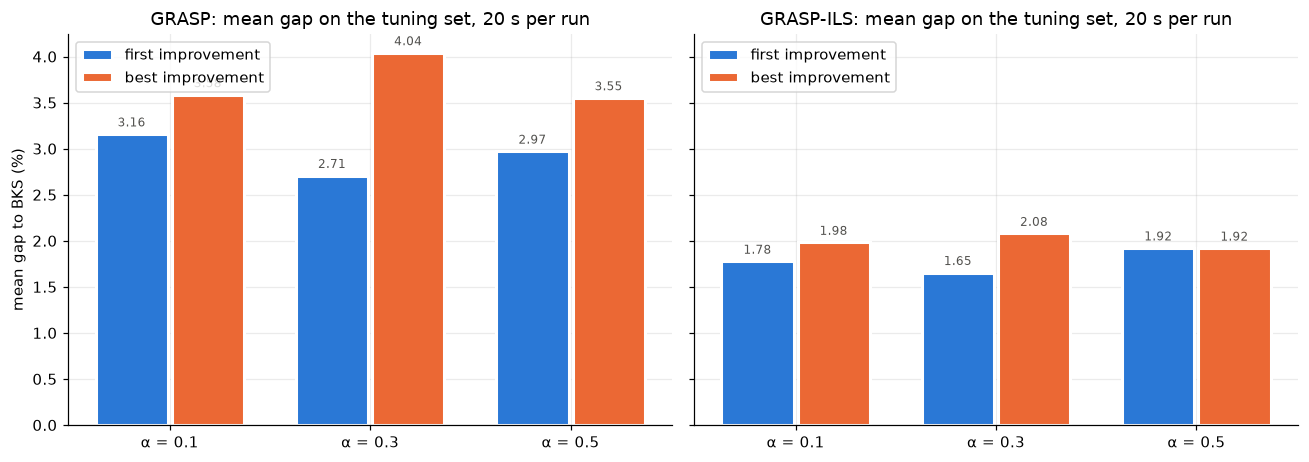

grasp tuning (mean gap %):
params
{'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}    1.65
{'alpha': 0.1, 'improvement': 'first', 'perturb_kicks': 90}    1.78
{'alpha': 0.5, 'improvement': 'best', 'perturb_kicks': 90}     1.92
{'alpha': 0.5, 'improvement': 'first', 'perturb_kicks': 90}    1.92
{'alpha': 0.1, 'improvement': 'best', 'perturb_kicks': 90}     1.98
{'alpha': 0.3, 'improvement': 'best', 'perturb_kicks': 90}     2.08
{'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 0}     2.71
{'alpha': 0.5, 'improvement': 'first', 'perturb_kicks': 0}     2.97
{'alpha': 0.1, 'improvement': 'first', 'perturb_kicks': 0}     3.16
{'alpha': 0.5, 'improvement': 'best', 'perturb_kicks': 0}      3.55
{'alpha': 0.1, 'improvement': 'best', 'perturb_kicks': 0}      3.58
{'alpha': 0.3, 'improvement': 'best', 'perturb_kicks': 0}      4.04

Chosen parameters for the test campaign: {'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}
Best plain GRASP setting: alpha 0.3, first impro

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, variant in zip(axes, ["GRASP", "GRASP-ILS"]):
    s = summary6[summary6.variant == variant]
    for k, (im, color) in enumerate((("first", "#2a78d6"), ("best", "#eb6834"))):
        v = s[s.improvement == im].set_index("alpha").reindex([0.1, 0.3, 0.5])
        xs = np.arange(3) + (k - 0.5) * 0.38
        ax.bar(xs, v.mean_gap, 0.36, color=color, label=f"{im} improvement", edgecolor="white", linewidth=2)
        for xi, g in zip(xs, v.mean_gap):
            ax.text(xi, g + 0.05, f"{g:.2f}", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_xticks(range(3), ["α = 0.1", "α = 0.3", "α = 0.5"])
    ax.set_title(f"{variant}: mean gap on the tuning set, {TIME_LIMIT:.0f} s per run")
    ax.legend(loc="upper left")
axes[0].set_ylabel("mean gap to BKS (%)")
plt.tight_layout(); plt.show()

CHOSEN = study.best_params(tuning, "grasp")
best_plain = summary6[summary6.variant == "GRASP"].iloc[0]
best_ils = summary6[summary6.variant == "GRASP-ILS"].iloc[0]
print(f"\nChosen parameters for the test campaign: {CHOSEN}")
print(f"Best plain GRASP setting: alpha {best_plain.alpha}, {best_plain.improvement} improvement, "
      f"mean gap {best_plain.mean_gap:.2f} %")
print(f"Best GRASP-ILS setting  : alpha {best_ils.alpha}, {best_ils.improvement} improvement, "
      f"mean gap {best_ils.mean_gap:.2f} %")

Read the two panels side by side: the right one (GRASP-ILS) against the left one (plain GRASP)
answers "more starts or deeper starts at the same 20 s?", and within each panel the bars show
the effect of $\alpha$ and of first vs best improvement. The printed lines give the numbers.

### 6.1 Plain GRASP vs GRASP-ILS per tuning instance (equal time)

In [ ]:
a, im = CHOSEN["alpha"], CHOSEN["improvement"]
pair = (tuning[(tuning.alpha == a) & (tuning.improvement == im)]
        .pivot_table(index="instance", columns="variant", values="gap", aggfunc="mean")
        .reindex(TUNING))
pair["difference (pts)"] = pair["GRASP"] - pair["GRASP-ILS"]
display(pair.round(2))
better = int((pair["difference (pts)"] > 1e-9).sum())
print(f"alpha {a}, {im} improvement: GRASP-ILS is better on {better} of {len(pair)} tuning "
      f"instances; mean gap {pair['GRASP'].mean():.2f} % (GRASP) vs {pair['GRASP-ILS'].mean():.2f} % (GRASP-ILS).")

variant,GRASP,GRASP-ILS,difference (pts)
instance,,,
C101,0.00,0.00,0.00
C201,0.00,0.00,0.00
R101,0.58,0.00,0.58
R201,5.76,4.21,1.55
RC101,2.91,1.92,0.98
RC201,7.00,3.79,3.21


alpha 0.3, first improvement: GRASP-ILS is better on 4 of 6 tuning instances; mean gap 2.71 % (GRASP) vs 1.65 % (GRASP-ILS).


## 7. Test campaign: 50 instances × 10 seeds × 20 s

The chosen parameters run on the 50 test instances with seeds 1 to 10, through the same
`study.run` as Tabu Search. The CSV `results/solomon_benchmark_grasp.csv` has the same columns
as the Tabu Search one, so notebook 03 can put them side by side.

In [ ]:
bench_csv = RESULTS / f"solomon_benchmark_grasp{TAG}.csv"
if RECOMPUTE:
    jobs = [j for j in study.test_jobs({"grasp": CHOSEN}) if j[3] in TEST_SEEDS]
    t0 = time.perf_counter()
    bench = study.run(with_limit(jobs), bench_csv)
    print(f"campaign wall time: {(time.perf_counter() - t0) / 60:.1f} min")
else:
    bench = pd.read_csv(bench_csv)
bench["class"] = bench.instance.str[:-2]  # C101 -> C1, RC205 -> RC2
bench["family3"] = bench["class"].str[:-1]
bench["bks_routes"] = bench.instance.map(instances.set_index("Dataset")["BKS routes"])
print(f"{len(bench)} runs on {bench.instance.nunique()} instances, seeds {sorted(bench.seed.unique().tolist())}")
print(f"feasible: {bench.feasible.mean():.0%}   runtime per run: mean {bench.seconds.mean():.1f} s, "
      f"max {bench.seconds.max():.1f} s (limit {TIME_LIMIT:.0f} s)")

500 runs x 20 s on 7 workers, Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
25/500
50/500
75/500
100/500
125/500
150/500
175/500
200/500
225/500
250/500
275/500
300/500
325/500
350/500
375/500
400/500
425/500
450/500
475/500
500/500
campaign wall time: 24.1 min
500 runs on 50 instances, seeds [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
feasible: 100%   runtime per run: mean 20.0 s, max 20.2 s (limit 20 s)


### 7.1 Results per instance (over the seeds)

In [ ]:
per_inst = (bench.groupby(["class", "instance"])
                 .agg(BKS=("best_known", "first"), best=("cost", "min"), mean=("cost", "mean"),
                      gap_best=("gap", "min"), gap_mean=("gap", "mean"), gap_std=("gap", "std"),
                      routes=("routes", "mean"), bks_routes=("bks_routes", "first"),
                      seconds=("seconds", "mean"))
                 .reset_index())
per_inst.round(2)

,class,instance,BKS,best,mean,gap_best,gap_mean,gap_std,routes,bks_routes,seconds
0,C1,C102,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.02
1,C1,C103,826.3,826.3,826.30,0.00,0.00,0.00,10.0,10,20.02
2,C1,C104,822.9,822.9,826.28,0.00,0.41,0.72,10.0,10,20.04
3,C1,C105,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.03
4,C1,C106,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.01
5,C1,C107,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.01
6,C1,C108,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.02
7,C1,C109,827.3,827.3,827.30,0.00,0.00,0.00,10.0,10,20.03
8,C2,C202,589.1,589.1,589.10,0.00,0.00,0.00,3.0,3,20.02
9,C2,C203,588.7,588.7,588.70,0.00,0.00,0.00,3.0,3,20.04


## 8. Results and visualization

### 8.1 Gap per class

,instances,mean_gap,median_gap,worst_gap,runs_le_7,routes,bks_routes,seconds
class,,,,,,,,
C1,8,0.05,0.00,2.41,100.00,10.00,10.00,20.02
C2,7,0.08,0.00,0.60,100.00,3.00,3.00,20.02
R1,11,1.04,0.91,3.60,100.00,12.69,12.64,20.03
R2,10,3.11,3.02,8.06,98.00,3.77,5.20,20.03
RC1,7,2.08,1.92,4.82,100.00,12.77,12.14,20.03
RC2,7,3.31,2.97,9.51,94.29,4.61,5.86,20.02


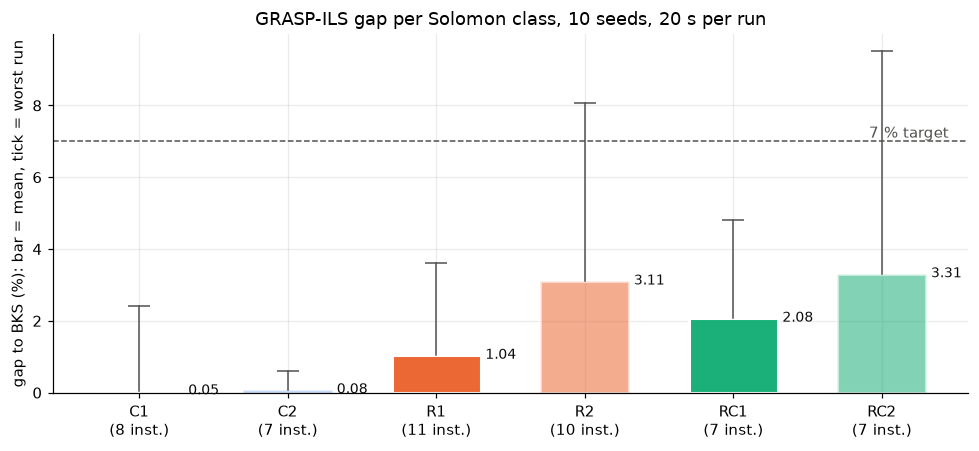

In [ ]:
cls = (bench.groupby("class")
            .agg(instances=("instance", "nunique"), mean_gap=("gap", "mean"),
                 median_gap=("gap", "median"), worst_gap=("gap", "max"),
                 runs_le_7=("gap", lambda g: 100 * (g <= 7).mean()),
                 routes=("routes", "mean"), bks_routes=("bks_routes", "mean"),
                 seconds=("seconds", "mean"))
            .reindex(CLASSES))
display(cls.round(2))

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, c in enumerate(CLASSES):
    color, light = FAMILY_COLOR[c[:-1]], c.endswith("2")
    ax.bar(i, cls.loc[c, "mean_gap"], 0.6, color=color, alpha=0.55 if light else 1.0,
           edgecolor="white", linewidth=2)
    ax.plot([i, i], [cls.loc[c, "mean_gap"], cls.loc[c, "worst_gap"]], color="#52514e", lw=1)
    ax.plot(i, cls.loc[c, "worst_gap"], "_", ms=14, color="#52514e")
    ax.text(i + 0.33, cls.loc[c, "mean_gap"], f"{cls.loc[c, 'mean_gap']:.2f}", va="center",
            fontsize=9, color="#0b0b0b")
ax.axhline(7, ls="--", lw=1, color="#52514e")
ax.annotate("7 % target", (5.45, 7), ha="right", va="bottom", color="#52514e")
ax.set_xticks(range(6), [f"{c}\n({int(cls.loc[c, 'instances'])} inst.)" for c in CLASSES])
ax.set_ylabel("gap to BKS (%): bar = mean, tick = worst run")
ax.set_title(f"GRASP-ILS gap per Solomon class, {len(TEST_SEEDS)} seeds, {TIME_LIMIT:.0f} s per run")
plt.tight_layout(); plt.show()

In [ ]:
worst_class = cls.mean_gap.idxmax()
print(f"Lowest mean gap: {cls.mean_gap.idxmin()} ({cls.mean_gap.min():.2f} %). "
      f"Highest: {worst_class} ({cls.mean_gap.max():.2f} %). "
      f"Type 1 mean {bench[bench['class'].str.endswith('1')].gap.mean():.2f} %, "
      f"type 2 mean {bench[bench['class'].str.endswith('2')].gap.mean():.2f} %.")
print(f"Runs at or below 7 %: {100 * (bench.gap <= 7).mean():.1f} % of {len(bench)}; "
      f"worst run {bench.gap.max():.2f} % ({bench.loc[bench.gap.idxmax(), 'instance']}).")

Lowest mean gap: C1 (0.05 %). Highest: RC2 (3.31 %). Type 1 mean 1.02 %, type 2 mean 2.29 %.
Runs at or below 7 %: 98.8 % of 500; worst run 9.51 % (RC208).


### 8.2 Gap per instance

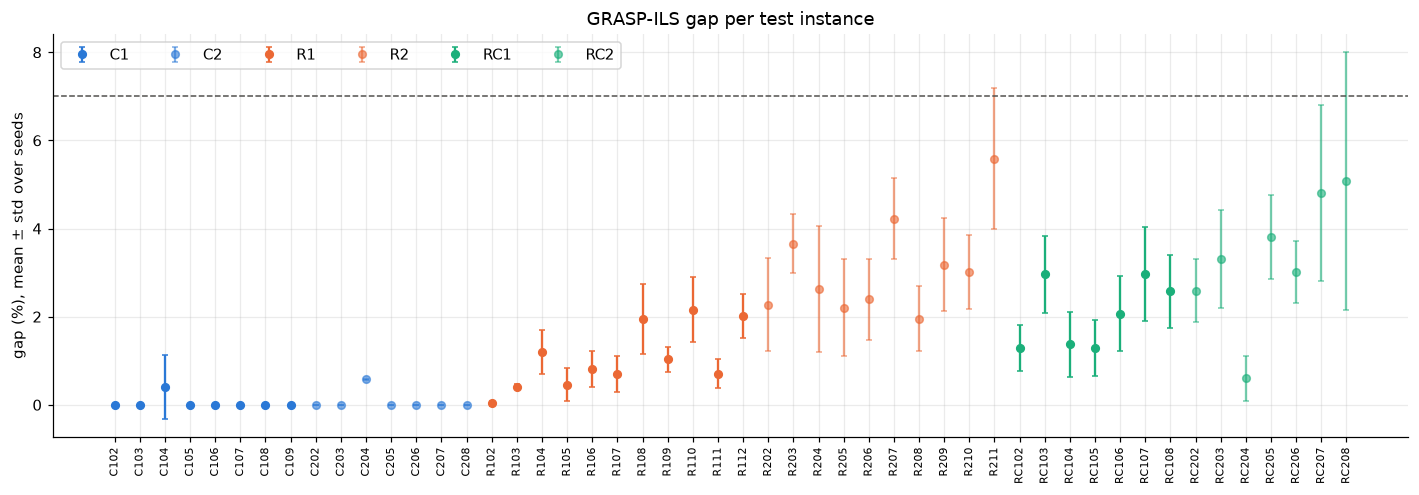

five hardest instances (mean gap %): R211 5.58, RC208 5.07, RC207 4.80, R207 4.22, RC205 3.81


In [ ]:
order = per_inst.sort_values(["class", "instance"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 4.6))
for c in CLASSES:
    s = order[order["class"] == c]
    color = FAMILY_COLOR[c[:-1]]
    ax.errorbar(s.index, s.gap_mean, yerr=s.gap_std, fmt="o", ms=5, capsize=2, color=color,
                alpha=0.6 if c.endswith("2") else 1.0, label=c)
ax.axhline(7, ls="--", lw=1, color="#52514e")
ax.set_xticks(order.index, order.instance, rotation=90, fontsize=7)
ax.set_ylabel("gap (%), mean ± std over seeds")
ax.set_title("GRASP-ILS gap per test instance")
ax.legend(ncol=6, loc="upper left")
plt.tight_layout(); plt.show()
hard = per_inst.nlargest(5, "gap_mean")[["instance", "gap_mean", "gap_std"]]
print("five hardest instances (mean gap %):", ", ".join(f"{r.instance} {r.gap_mean:.2f}" for r in hard.itertuples()))

### 8.3 Runtime and number of iterations

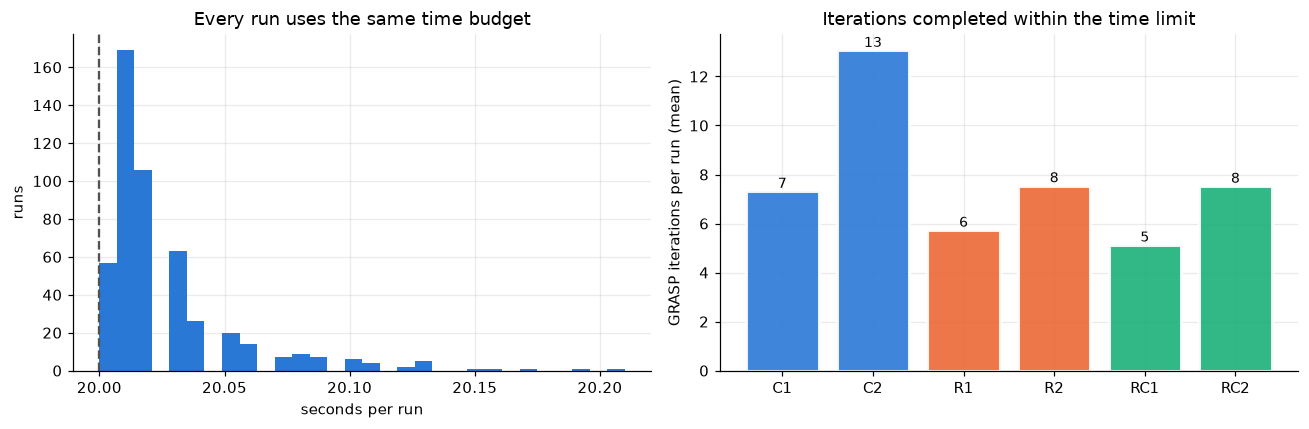

runtime: 20.00 to 20.21 s; iterations per run: C1 7, C2 13, R1 6, R2 8, RC1 5, RC2 8


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(bench.seconds, bins=30, color="#2a78d6")
axes[0].axvline(TIME_LIMIT, ls="--", color="#52514e")
axes[0].set_xlabel("seconds per run"); axes[0].set_ylabel("runs")
axes[0].set_title("Every run uses the same time budget")
it = bench.groupby("class").iterations.mean().reindex(CLASSES)
axes[1].bar(range(6), it, color=[FAMILY_COLOR[c[:-1]] for c in CLASSES],
            alpha=0.9, edgecolor="white", linewidth=2)
for i, v in enumerate(it):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9)
axes[1].set_xticks(range(6), CLASSES); axes[1].set_ylabel("GRASP iterations per run (mean)")
axes[1].set_title("Iterations completed within the time limit")
plt.tight_layout(); plt.show()
print(f"runtime: {bench.seconds.min():.2f} to {bench.seconds.max():.2f} s; iterations per run: "
      + ", ".join(f"{c} {v:.0f}" for c, v in it.items()))

The runtime is fixed by the protocol; what changes between classes is how many GRASP iterations
fit in it: long type 2 routes make each local search slower, so fewer starts are explored.

### 8.4 Stability across seeds

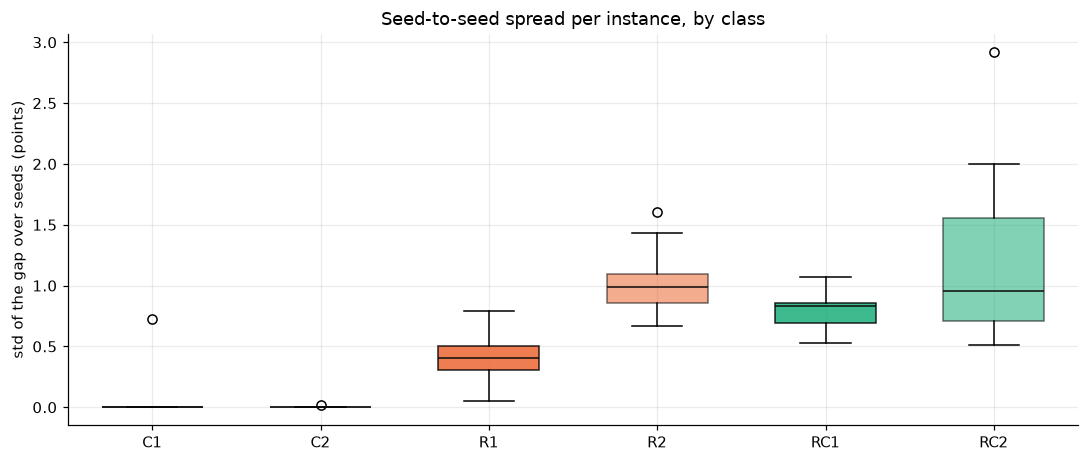

median seed-to-seed std: 0.58 points; largest: 2.92 (RC208)


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.3))
data = [bench[bench["class"] == c].groupby("instance").gap.std().values for c in CLASSES]
bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": "#0b0b0b"})
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(FAMILY_COLOR[c[:-1]]); patch.set_alpha(0.55 if c.endswith("2") else 0.85)
ax.set_xticks(range(1, 7), CLASSES)
ax.set_ylabel("std of the gap over seeds (points)")
ax.set_title("Seed-to-seed spread per instance, by class")
plt.tight_layout(); plt.show()
spread = bench.groupby("instance").gap.std()
print(f"median seed-to-seed std: {spread.median():.2f} points; largest: {spread.max():.2f} ({spread.idxmax()})")

### 8.5 Computation time against instance size

,n,routes,feasible,seconds per iteration
0,100,6,True,0.04
1,200,12,True,0.11
2,400,23,True,0.42
3,1000,54,True,3.42
4,2000,111,True,17.97


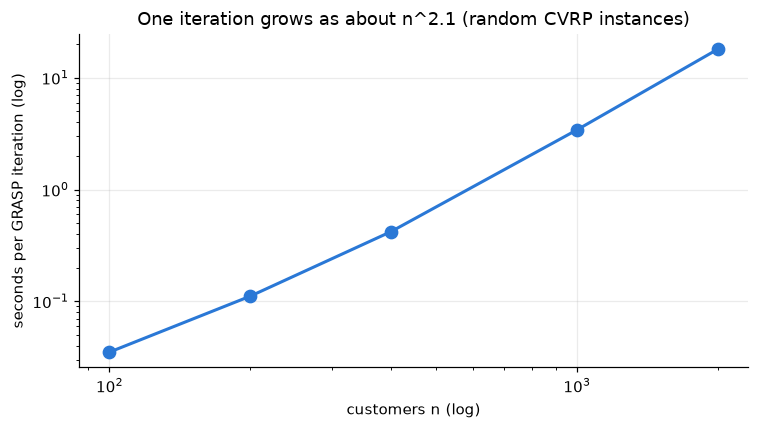

In [ ]:
scale_rows = []
for n in (100, 200, 400, 1000, 2000):
    inst = Instance.random(n, capacity=100, seed=1)
    r = grasp(inst, GRASPParams(iterations=2), seed=1)
    scale_rows.append({"n": n, "routes": len(r.best), "feasible": r.best.is_feasible(inst),
                       "seconds per iteration": r.runtime / r.iterations})
scale = pd.DataFrame(scale_rows)
slope = np.polyfit(np.log(scale.n), np.log(scale["seconds per iteration"]), 1)[0]
display(scale.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(scale.n, scale["seconds per iteration"], "o-", lw=2, ms=8, color="#2a78d6")
ax.set_xlabel("customers n (log)"); ax.set_ylabel("seconds per GRASP iteration (log)")
ax.set_title(f"One iteration grows as about n^{slope:.1f} (random CVRP instances)")
plt.tight_layout(); plt.show()

Random CVRP instances of growing size (no time windows), one construction and local search
each: the fitted exponent is the empirical complexity of one iteration, which shows that
instances of several thousand customers stay solvable, as the brief requires.

## 9. Statistical performance analysis

Unit of analysis: the instance (team design). For each class: the mean gap with a 95 %
confidence interval over the per-instance means (Student $t$), the share of runs at or under
7 %, and the spread over seeds. The comparison with Tabu Search and SA (Friedman test with Holm
correction) is done in notebook 03 on the shared CSV files.

In [ ]:
def ci95(v):
    v = np.asarray(v, dtype=float)
    return stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.nan

inst_means = bench.groupby(["class", "instance"]).gap.mean().reset_index()
table9 = (inst_means.groupby("class").gap
          .agg(instances="size", mean="mean", ci95=ci95, min="min", max="max").reindex(CLASSES))
table9.loc["all 50"] = [inst_means.gap.size, inst_means.gap.mean(), ci95(inst_means.gap),
                        inst_means.gap.min(), inst_means.gap.max()]
display(table9.round(2))

w = stats.wilcoxon(pair["GRASP"], pair["GRASP-ILS"], alternative="greater", zero_method="zsplit")
print(f"Plain GRASP vs GRASP-ILS on the {len(pair)} tuning instances (alpha {a}, {im}, equal time): "
      f"Wilcoxon W = {w.statistic:.1f}, p = {w.pvalue:.3f}. With 6 instances the smallest "
      f"possible p is 1/64 = 0.016, so this test is indicative only.")

,instances,mean,ci95,min,max
class,,,,,
C1,8,0.05,0.12,0.00,0.41
C2,7,0.08,0.20,0.00,0.58
R1,11,1.04,0.48,0.03,2.16
R2,10,3.11,0.80,1.95,5.58
RC1,7,2.08,0.71,1.29,2.97
RC2,7,3.31,1.39,0.60,5.07
all 50,50,1.63,0.44,0.00,5.58


Plain GRASP vs GRASP-ILS on the 6 tuning instances (alpha 0.3, first, equal time): Wilcoxon W = 19.5, p = 0.062. With 6 instances the smallest possible p is 1/64 = 0.016, so this test is indicative only.


## 10. Conclusions

The numbers below are computed from the results above, so they always match the run.

In [ ]:
t1 = bench[bench["class"].str.endswith("1")].gap
t2 = bench[bench["class"].str.endswith("2")].gap
lines = [
    f"- Feasibility: {bench.feasible.mean():.0%} of the {len(bench)} test runs are feasible "
    f"(checked by the shared evaluator).",
    f"- Quality: mean gap {bench.gap.mean():.2f} % over the 50 test instances "
    f"(type 1: {t1.mean():.2f} %, type 2: {t2.mean():.2f} %); best class {cls.mean_gap.idxmin()} "
    f"({cls.mean_gap.min():.2f} %), hardest class {cls.mean_gap.idxmax()} ({cls.mean_gap.max():.2f} %).",
    f"- Target: {100 * (bench.gap <= 7).mean():.1f} % of the runs are at or under 7 %; "
    f"the worst run is {bench.gap.max():.2f} % ({bench.loc[bench.gap.idxmax(), 'instance']}).",
    f"- Time: every run uses the {TIME_LIMIT:.0f} s budget (max {bench.seconds.max():.1f} s); "
    f"iterations per run range from {it.min():.0f} ({it.idxmin()}) to {it.max():.0f} ({it.idxmax()}).",
    f"- Tuning (equal time): chosen {CHOSEN}; GRASP-ILS beats plain GRASP on {better} of "
    f"{len(pair)} tuning instances ({pair['GRASP'].mean():.2f} % vs {pair['GRASP-ILS'].mean():.2f} %).",
    f"- Stability: median seed-to-seed std {spread.median():.2f} gap points.",
]
if QUICK_CHECK:
    lines.insert(0, "- QUICK_CHECK is on: 1 s runs, these numbers are NOT valid results.")
print("\n".join(lines))

- Feasibility: 100% of the 500 test runs are feasible (checked by the shared evaluator).
- Quality: mean gap 1.63 % over the 50 test instances (type 1: 1.02 %, type 2: 2.29 %); best class C1 (0.05 %), hardest class RC2 (3.31 %).
- Target: 98.8 % of the runs are at or under 7 %; the worst run is 9.51 % (RC208).
- Time: every run uses the 20 s budget (max 20.2 s); iterations per run range from 5 (RC1) to 13 (C2).
- Tuning (equal time): chosen {'alpha': 0.3, 'improvement': 'first', 'perturb_kicks': 90}; GRASP-ILS beats plain GRASP on 4 of 6 tuning instances (2.71 % vs 1.65 %).
- Stability: median seed-to-seed std 0.58 gap points.


**Limitations.**
- The benchmark objective is distance without traffic; the team model (notebook 01) minimizes
  duration with time-dependent traffic. GRASP only reads `inst.dist`, so a traffic evaluator can
  be plugged in, but its results are not covered here.
- Solomon instances all have 100 customers; scaling (Section 8.5) is measured on random CVRP
  instances, without time windows.
- We minimize distance only, so a solution can use more trucks than the hierarchical
  (fewest trucks first) best known solutions.
- The time budget is fixed at 20 s; with more time, more iterations would fit, especially on
  type 2 instances.

**Next steps.** Compare GRASP-ILS with Tabu Search and SA in notebook 03 (same CSV format);
for type 2, try more kicks per start or time-aware neighbor lists; path relinking between elite
solutions is a classical GRASP extension.

### References
- Feo, T. A., and Resende, M. G. C. (1995). Greedy randomized adaptive search procedures. *Journal of Global Optimization*, 6, 109-133.
- Resende, M. G. C., and Ribeiro, C. C. (2010). Greedy randomized adaptive search procedures: advances, hybridizations, and applications. *Handbook of Metaheuristics*, Springer.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254-265.
- Savelsbergh, M. W. P. (1992). The vehicle routing problem with time windows: minimizing route duration. *ORSA Journal on Computing*, 4(2), 146-154.
- Potvin, J.-Y., and Rousseau, J.-M. (1995). An exchange heuristic for routeing problems with time windows. *Journal of the Operational Research Society*, 46, 1433-1446.
- Taillard, É., et al. (1997). A tabu search heuristic for the vehicle routing problem with soft time windows. *Transportation Science*, 31(2), 170-186.
- Toth, P., and Vigo, D. (2003). The granular tabu search and its application to the vehicle-routing problem. *INFORMS Journal on Computing*, 15(4), 333-346.
- Kohl, N., et al. (1999). 2-path cuts for the vehicle routing problem with time windows. *Transportation Science*, 33(1), 101-116.